# First Property Purchase Loans
## Component 1: the business opportunity

**The product.** A housing loan for someone buying their first home. A bank can lend up to 75% of the property's value on a first housing loan (MAS, n.d.-a). On a S$630,000 four-room HDB resale flat, about the median (PropKaki, 2026), that is a loan of S$472,500.

**The customer segment.** Working adults aged 21 to 55 with earned income, who own no property and have no mortgage history. They are 72,292 of the bank's 307,511 past applicants (23.5%). They are early in their credit life: 61% are under 40, and 14% have no credit bureau file at all.

**How the segment uses the product.** One large loan, secured on the home (collateral, FA7.1 s10), taken out once to buy a first home and repaid monthly from earnings: about S$2,020 a month over 25 years at the portfolio rate of 2.08%. The rest of the price comes from their own funds and housing grants; first-timer families can receive up to S$120,000 in Enhanced CPF Housing Grant for a new flat (HDB, 2026).

**The opportunity.**
- **It earns well if risk is managed.** Each loan earns about S$11,950 of net interest over five years, but one default costs about S$94,500. On unseen applicants, the recommended cutoff earns S$41.4m per 10,000 applicants at a flat 2.00%, against S$32.6m for approving everyone (Component 6).
- **A customised scorecard suits this group.** Retail lending has many applicants and needs automation (FA7.1 s7), and a scorecard built for the bank's own customers and product can be a competitive advantage over a generic one (FA7.2 s13).
- **Standard criteria would miss many of them.** Those with no bureau file cannot be scored on bureau history, so they get their own scorecard (FA7.2 s9).

**How to run this project.** Keep these in one folder with the two raw data files, under the names they were supplied with (`IS453 Group Assignment - Application Data.csv`, `IS453 Group Assignment - Bureau Data.csv`) or as `App_Data.csv` and `Bureau_Data.csv`, and run in order: this notebook (Components 1-2), `IS453_Component_3.ipynb` (Component 3), then `IS453_Component_4_to_7.ipynb` (Components 4-7). Component 3 reads this notebook by its file name.


## How we selected the rows that represent our customer segment

Two rules for record selection guide every step (FA9.1 s18-19):
- **Select data from the same or similar products** (FA9.1 s18): the training data should look like the loan the bank is about to offer.
- **Represent future applicants** (FA9.1 s19): any group left out of training becomes lending policy, because the model never learns how to score that group.

0. Original data: 307,511 rows, 24,825 Bads, a bad rate of 8.07% (see the Step 0 code below).

Filters, applied to each prospective applicant:
1. Applicant owns no property.
2. Applicant has no mortgage or real estate loan in the bureau data, active or closed.
3. Applicant has earned income.
4. Applicant is aged 21 to 55.

We kept:
- Applicants with no bureau record.
- Revolving-loan borrowers (checkpoint feedback, see below).
- Rows with invalid or blank values, which are treated during data preparation rather than deleted.
- All genders, to avoid fair-lending problems (FA7.1 s14).

We considered and rejected:
- **Excluding everyone living in a "house/apartment"**: it would leave very few rows (17,904).
- **A minimum loan size**: any threshold is arbitrary, and the loans in this data are consumer-sized. Keeping only loans above the median lowers the bad rate to 8.14% and halves the sample to 35,767 rows.
- **Cash loans only** (FA9.1 s18): reversed after the professor's checkpoint feedback. First-time buyers use both products, and cash and revolving loans are not mutually exclusive: 61% of applicants with a bureau file hold both a credit card and instalment credit. Revolving loans are 7% of the segment (5,078 rows, 5.8% Bad against 9.5% for cash loans). Contract type has an IV of 0.015, so it does not enter the scorecard and does not distort it. A cash-only version (67,214 rows, 9.46% Bad) is kept as a sensitivity check.

Summary:
- Steps 1-2 define who counts as a first-time buyer.
- Steps 3-4 keep only applicants who could actually be eligible for the loan (earned income, age).

## The result

Number of rows:
- 72,292 rows, 6,652 Bads.

Percentage of Bads compared with the original data set:
- Bad rate of 9.20%, against 8.07% originally. This makes sense for younger borrowers with no property wealth.

## Our approach for merging the application and bureau data sets

The two tables have a one-to-many relationship: one applicant in `App_Data` has zero, one or many past credit lines in `Bureau_Data`. FA9.2 s4-8 sets out three options:
- **Option 1: left join directly** (FA9.2 s4-5). Not chosen, because it copies each applicant's label once per credit: 72,292 rows become 343,638 and the bad rate shifts to 8.83%. Applicants are duplicated (Goods 4.77 times, Bads 4.56 times), which creates artificial labelled rows and skews the results.
- **Option 2: one column per credit** (FA9.2 s6-7). Needs at least 232 columns, most of them empty.
- **Option 3: feature selection and engineering, then join** (FA9.2 s8). **Chosen.** Keep the bureau rows for our applicants, group them by `SK_ID_CURR`, and summarise each applicant's credit into **9** features. Each one matches a type of bureau variable on the course's list of scorecard parameters (FA7.2 s6-7):

1. **Payment history** (number of delinquencies): (1) whether any credit is currently overdue, which shows current payment trouble. 8.7% Bad if not overdue against 19.1% if overdue.
2. **Amounts owed** (total debt, total utilisation): (2) debt ratio = total debt ÷ total credit, using only credits whose debt is known; (3) number of active credits; (4) share of credits still active.
3. **Length of credit history** (time at bureau, total trades): (5) average credit age; (6) total number of credits; (7) number of closed credits.
4. **New credit** (trades opened recently): (8) most recent credit; (9) number of credits opened in the last 24 months.

Step (xii) then builds **2 more** bureau features in a separate table, so the bureau file gives **11** features in all:
10. **Payment history**: (10) adverse history = overdue now, an overdue amount ever recorded, or a credit sold or written off.
11. **Amounts owed** (total utilisation): (11) credit card utilisation = card debt ÷ card credit.


- Then left-join the one-row-per-applicant table onto the segment using **SK_ID_CURR**, and add a flag for applicants with no bureau record instead of filling their blanks with 0, because 0 would mean "has credit, owes nothing".
- Total number of credits (checkpoint feedback): kept and tested at every stage, together with its active and closed parts, see (x). On its own its IV is too weak to go forward (0.012); the share of credits still active (active ÷ total) carries the same information to Component 3, and Component 4 removes it in tuning round 3 because the AUC does not change without it (FA11.4 s5).

## Issues with the dataset
- The historical cash loans run a median of about 21 months (credit ÷ annuity), against 20-30 years for a mortgage, so they are a proxy for property loans. **Assumption:** no dataset holds mortgage outcomes for first-time buyers, so default on a ~21-month consumer loan is used as a proxy for mortgage default risk.
- The bureau does not capture every property purchase (see Step 2).
- 1,986 bureau credits show negative debt; data preparation treats these as invalid and sets them to missing (FA9.1 s7-8).
- 0.08% of credits are in another currency (FA9.1 s4).

## Assumptions and limitations (shared with Components 1 and 6 and the limitations slide)

**What "bad" means.** `TARGET` = 1 if the client had payment difficulties: a late payment of more than X days on at least one of the first Y instalments (data dictionary). It is not necessarily a default or write-off. "Bad" here is an earlier, more frequent event than default, which partly explains why the bad rate (9.2%) is much higher than typical mortgage default rates.

**Ranking vs level.** The scorecard is trained on short consumer loans. We assume it *ranks* first-time buyers correctly: a low score means a higher risk of payment difficulties on a mortgage too. We do not assume the 9.2% bad rate is the mortgage default rate. The profit calculation in Component 6 uses the bad rates as observed, which is conservative, and then tests how the cutoff moves under other loss and spread assumptions.

**Business inputs.** Loan size, interest rate, costs and the loss given default are business assumptions. They are set and tested in Component 6 (settings cell and section E), not here.

**Sample bias (FA9.1 s19).** The data only contains applicants who were approved and given a loan, so we only see outcomes for people the bank already accepted. Rejected applicants, likely the riskier ones, are not in the data. The scorecard may therefore underestimate risk for the weakest applicants, and this is listed as a limitation.

**Context and affordability.** The bank operates under Singapore rules: MAS LTV limits, a Mortgage Servicing Ratio of 30% for HDB and EC purchases, and a Total Debt Servicing Ratio of 55% (MAS, n.d.-a; MAS, n.d.-b). These are applied as pre-screens at application, not inside the scorecard. The data is not in SGD and contains no mortgage repayment, so MSR and TDSR cannot be calculated here.

**No minimum income.** We deliberately set no minimum income. A key part of this segment is young first-time buyers, such as recent university graduates, who are working but earn a starting salary. A minimum income filter would remove them from training, and the scorecard would never learn to score them (FA9.1 s19). Applicants with no earned income (students, unemployed) are excluded in Step 3, because a mortgage must be repaid from earnings.

**Decisions made by the group**
1. Age cap: 55 (a loan of at least 10 years still ends by 65 - see Step 4).
2. Total number of credits: kept and tested with its active and closed parts - see (x). Too weak on its own (IV 0.012); its information goes forward as the share of credits still active, which Component 4 removes in tuning because the AUC does not change without it.
3. Negative debt: treated as missing (invalid value, FA9.1), not set to 0. Credits with unknown debt are left out of both the top and the bottom of the debt ratio. Foreign-currency credits (0.08%) are kept and stated as a limitation.


# Codes for the project

## STAGE A: SELECTING THE SEGMENT
## Step 0: Load data & get baseline

In [1]:
import warnings
import pandas as pd
import numpy as np

warnings.filterwarnings('ignore')
from pathlib import Path

ORIGINAL_NAMES = {'App_Data.csv': 'IS453 Group Assignment - Application Data.csv',
                  'Bureau_Data.csv': 'IS453 Group Assignment - Bureau Data.csv'}

def raw_file(name):
    # the raw file under our short name or the name it was supplied with, in any capitalisation
    for candidate in (name, ORIGINAL_NAMES[name]):
        found = next((p for p in Path('.').iterdir() if p.name.lower() == candidate.lower()), None)
        if found:
            return found
    raise FileNotFoundError(f"Put {name} or '{ORIGINAL_NAMES[name]}' in {Path.cwd()}")


app_data = pd.read_csv(raw_file('App_Data.csv'))
bureau_data = pd.read_csv(raw_file('Bureau_Data.csv'))

# comparing the bad rate with the original data
print(app_data.shape, bureau_data.shape)  #lab 1 - shows the rows and columns of both datasets
print(app_data['TARGET'].value_counts())  #Lab 7 c18 - shows the # of bads in TARGET column
print(app_data['TARGET'].mean()) # mean of 0/1 = gives bad rate directly, since 1 is bad

app_data = app_data.copy()  # defragments the table (avoids PerformanceWarning)
app_data['AGE_YEARS'] = -app_data['DAYS_BIRTH'] / 365.25 #Lab 7 - divide by 365.25 (to account for leap years) to convert to years for Step 4

(307511, 120) (1716428, 17)
TARGET
0    282686
1     24825
Name: count, dtype: int64
0.08072881945686496


## Step 1: Applicant owns no property (FLAG_OWN_REALTY = N)

This defines a first-time buyer as someone who owns nothing at the point of applying.

Existing owners are upgrading or investing, with home equity as a cushion (collateral, FA7.1 s10), which is a different risk profile.

FA9.1 s18 says to select data from the same or similar products. We use the ownership flag (`FLAG_OWN_REALTY`) instead of `NAME_HOUSING_TYPE`, because the two contradict each other: housing type describes the dwelling, not who owns it. Housing type is still useful later as a candidate predictor.

Results
- Rows decrease from 307,511 to 94,199.
- Bads decrease from 24,825 to 7,842.
- The bad rate moves from 8.07% to 8.32%.

The flag is self-declared and cannot be verified. Step 2 checks it against the bureau data.

In [2]:
# check which column describes ownership reliably
print(app_data.groupby('NAME_HOUSING_TYPE')['FLAG_OWN_REALTY'].value_counts().unstack()) #Lab 7 .groupby().value_counts()

# check if owners and non-owners differ in risk
print(app_data.groupby('FLAG_OWN_REALTY')['TARGET'].mean()) # Lab 7 .groupby()

# filter App_Data dataset
seg1 = app_data[app_data['FLAG_OWN_REALTY'] == 'N']  # Lab 7 - boolean filter
print(len(seg1), seg1['TARGET'].sum(), seg1['TARGET'].mean())

FLAG_OWN_REALTY          N       Y
NAME_HOUSING_TYPE                 
Co-op apartment        424     698
House / apartment    73671  199197
Municipal apartment   6822    4361
Office apartment      1224    1393
Rented apartment      2795    2086
With parents          9263    5577
FLAG_OWN_REALTY
N    0.083249
Y    0.079616
Name: TARGET, dtype: float64
94199 7842 0.08324929139375152


*Code annotation*

**Code 1: do housing type and the ownership flag agree?**
- `.groupby(A)[B]` looks at column B inside each group of A. Here it splits applicants into one group per housing type, then looks at the ownership flag within each group.
- `value_counts()` counts the Ys and Ns in each group. The result is a list with two levels of labels (housing type, then flag).
- `unstack()` turns the inner level (N/Y) into columns, giving the table shown.

5,577 applicants living with parents say they own property (Y), and 73,671 living in a house/apartment say they do not (N). These are the contradictions that make housing type unreliable as an ownership test.

**Code 2: bad rate by ownership flag**
- `groupby()[]` splits applicants into the Y and N groups of `FLAG_OWN_REALTY`, then looks at `TARGET` in each.
- `TARGET` is 1 or 0, so its mean is the bad rate of each group.

7.96% is the bad rate of the rows this step removes (the owners).

**Code 3: apply the filter**
- `app_data['FLAG_OWN_REALTY'] == 'N'` compares each row's flag with N and gives True or False per row: 213,312 False and 94,199 True.
- `len(seg1)` counts the rows that remain, `seg1['TARGET'].sum()` adds up the 1s to count Bads, and `.mean()` gives the bad rate.

**First filter: 213,312 rows are removed. 94,199 rows remain, with 7,842 Bads and a bad rate of 8.32%.**

## Step 2: Applicant has no mortgage or real estate loan in the bureau data, active or closed

Step 1 asks whether the applicant owns a property now. Step 2 asks whether the applicant has ever financed one. A first-purchase applicant must have done neither.

This removes 3,991 applicants: 2,866 with an active mortgage, which contradicts their ownership flag (an inconsistency in the data, FA9.1 s4), and 1,125 returning buyers whose property loans are closed or paid off. This group defaults at 4.9%, so keeping them would make first-time buyers look safer than they are (8.5% for those who remain).

We keep the 12,550 applicants with no bureau record, who default at 10.6%. Having no record does not mean having no mortgage, but excluding them would build a lending policy into the data (FA9.1 s19).

Results
- Rows decrease from 94,199 to 90,208.
- Bads decrease from 7,842 to 7,646.
- The bad rate moves from 8.32% to 8.48%.

However, owners who say they own property show a mortgage in the bureau only 4.8% of the time. The bureau does not record every property purchase, so this step removes clear contradictions rather than checking full histories.

In [3]:
# Which credit types exist? Find the property-related ones by reading labels
print(bureau_data['CREDIT_TYPE'].value_counts())       # Lab 7

# List of applicant IDs who EVER had a property loan
prop_types = ['Mortgage', 'Real estate loan']
is_prop = bureau_data['CREDIT_TYPE'].isin(prop_types)  # Lab 7 .isin - checks
prior_prop_ids = (bureau_data.loc[is_prop, 'SK_ID_CURR'].unique()) # drops repeats

# Flag applicants in seg1 who are on that list, and compare risk
has_prop = seg1['SK_ID_CURR'].isin(prior_prop_ids)
print(seg1.groupby(has_prop)['TARGET'].agg(['count', 'mean']))   # count and bad rate in one step

# Filter - Keep only those NOT on the list
seg2 = seg1[~has_prop]                                  # ~ means NOT

# Check (not a filter): how many have no bureau record?
no_bureau = ~seg2['SK_ID_CURR'].isin(bureau_data['SK_ID_CURR']) # applicants with no bureau record
print(no_bureau.sum(), seg2.loc[no_bureau, 'TARGET'].mean()) # no bureau record

CREDIT_TYPE
Consumer credit                                 1251615
Credit card                                      402195
Car loan                                          27690
Mortgage                                          18391
Microloan                                         12413
Loan for business development                      1975
Another type of loan                               1017
Unknown type of loan                                555
Loan for working capital replenishment              469
Cash loan (non-earmarked)                            56
Real estate loan                                     27
Loan for the purchase of equipment                   19
Loan for purchase of shares (margin lending)          4
Mobile operator loan                                  1
Interbank credit                                      1
Name: count, dtype: int64
            count     mean
SK_ID_CURR                
False       90208  0.08476
True         3991  0.04911
12550 0.106135

*Code annotation*

**Block 1: which credit types exist?**
- Lists every credit type, to find the property-related ones: 18,391 mortgages and 27 real estate loans, 18,418 property credits in total.

**Block 2: who has ever had a property loan?**
- `prop_types` stores the two property credit types in a list.
- `is_prop` marks every bureau row that is a property loan: `isin(prop_types)` asks of each row whether its credit type is one of the two, and returns True or False.
- `prior_prop_ids` turns those rows into a list of applicant IDs: `.loc[is_prop, 'SK_ID_CURR']` keeps the IDs on the True rows, and `.unique()` keeps each ID once.
- The 18,418 property credits belong to 16,877 different applicants.

**Block 3: compare their risk**
- `has_prop` flags the applicants in `seg1` whose ID is on that list (True or False for each applicant).
- `groupby(has_prop)` splits applicants into the two groups, and `.agg(['count', 'mean'])` gives each group's size and bad rate in one step.
- 3,991 applicants are flagged, with a bad rate of 4.91%.

**Block 4: apply the filter**
- `~` flips True and False, so `seg1[~has_prop]` keeps the applicants **not** on the list.

**Second filter: 3,991 rows are removed. 90,208 rows remain, with 7,646 Bads and a bad rate of 8.48%.**

**Block 5 (a check, removes nothing): applicants with no bureau record**
- `no_bureau` marks applicants whose ID does not appear in the bureau file; `.sum()` counts them.
- `.loc[no_bureau, 'TARGET'].mean()` gives their bad rate.
- 12,550 applicants have no bureau record, with a bad rate of 10.6%.

## Step 3: Applicant has earned income

A property loan is repaid from regular earnings over many years (capacity in 5Cs, FA7.1 s10)

The borrower MUST be able to repay a LT loan from earnings.

Every row carrying the invalid DAYS_EMPLOYED = 365243 placeholder is removed (for pensioners and unemployed)
- Pensioner (13,003 rows, 5.6% BAD rate) is removed. Median age = 60, cannot take on LT loan, few are first time buyers.
- Unemployed (7 rows, 28.6% BAD) - no income to repay loan
- Student (8 rows, 0% BAD) - no income, too few rows to estimate a rate
- Maternity leave (1 row, 0% BAD) - temporary absence of earned income

Results
- Rows decrease from 90,208 to 77,189.
- Bads decrease from 7,646 to 6,917.
- The bad rate moves from 8.48% to 8.96%.


In [4]:
# 1. Risk and size by income type
print(seg2.groupby('NAME_INCOME_TYPE')['TARGET'].agg(['count', 'mean']))

# 2. Where does the 365243 placeholder sit?
print(seg2.groupby('NAME_INCOME_TYPE')['DAYS_EMPLOYED'].max())   # Lab 7

# 3. Filter
earned = ['Working', 'Commercial associate', 'State servant', 'Businessman']
seg3 = seg2[seg2['NAME_INCOME_TYPE'].isin(earned)]               # isin
print(len(seg3), seg3['TARGET'].sum(), seg3['TARGET'].mean())

                      count      mean
NAME_INCOME_TYPE                     
Businessman               2  0.000000
Commercial associate  21289  0.074780
Maternity leave           1  0.000000
Pensioner             13003  0.055910
State servant          6995  0.060758
Student                   8  0.000000
Unemployed                7  0.285714
Working               48903  0.100198
NAME_INCOME_TYPE
Businessman              -1766
Commercial associate        -2
Maternity leave          -3762
Pensioner               365243
State servant               -3
Student                   -191
Unemployed              365243
Working                      0
Name: DAYS_EMPLOYED, dtype: int64
77189 6917 0.08961121403308761


*Code annotation*

**Line 1: risk and size by income type**
- For each income type, shows the number of applicants and the bad rate.
- 13,003 + 7 + 8 + 1 = 13,019 rows are removed, with a combined bad rate of 5.6%.

**Line 2: the invalid employment value**
- Shows the largest `DAYS_EMPLOYED` value for each income type. Real values are negative (days before applying), so the largest is the one closest to zero.
- Only the unemployed and pensioners have positive values, and their maximum of 365,243 days (about 1,000 years) is impossible: it is a placeholder for "not employed" (an invalid value, FA9.1 s7).

**Line 3: apply the filter**
- `earned` lists the four income types that come from earnings.
- `seg3` keeps applicants whose income type is one of those four.

## Step 4: Applicant is aged 21 to 55

Lending policy rule:
- **21** is the standard minimum borrowing age, and also HDB's minimum age for couples buying a flat (HDB, n.d.). After Steps 1-3 the youngest applicant is already 21.0, so the lower bound removes no one.
- **55** means a loan of at least 10 years still ends by 65, the age beyond which MAS lowers the LTV limit (MAS, n.d.-a). Singapore's minimum retirement age is 64 from 1 July 2026 (Ministry of Manpower, n.d.). A 10-year tenor is short for a mortgage, so this is a deliberately generous cap.
- Risk falls steadily with age. Removing the 4,897 applicants above 55 removes a group that defaults at 5.4%.
- **Age is an eligibility filter, not a scorecard input.** Within the 21-55 range age still ranks risk (11.4% Bad at 21-29 against 7.0% at 46-55), so it was screened as a candidate in Component 3. Component 4 leaves it out of the scorecard on purpose, because it is a protected characteristic (lending bias, FA7.1 s14). Age is used afterwards only to check that no age group is shut out by the scorecard.

Results
- Rows decrease from 77,189 to 72,292.
- Bads decrease from 6,917 to 6,652.
- The bad rate moves from 8.96% to 9.20%.

In [5]:
# 1. Bad rate by 5-year age band
age_band = pd.cut(seg3['AGE_YEARS'], bins=[20, 25, 30, 35, 40, 45, 50, 55, 60, 70])   # L10
print(seg3.groupby(age_band, observed=False)['TARGET'].agg(['count', 'mean']))

# 2. Filter with two conditions
seg = seg3[(seg3['AGE_YEARS'] >= 21) & (seg3['AGE_YEARS'] <= 55)]                               
print(len(seg), seg['TARGET'].sum(), seg['TARGET'].mean())

# extra: checking the loan type mix of the final segment
print(seg.groupby('NAME_CONTRACT_TYPE')['TARGET'].agg(['count', 'mean']))

           count      mean
AGE_YEARS                 
(20, 25]    4438  0.119874
(25, 30]   12458  0.111655
(30, 35]   13489  0.103343
(35, 40]   13470  0.093764
(40, 45]   12252  0.076885
(45, 50]    8300  0.073012
(50, 55]    7885  0.066455
(55, 60]    3572  0.057391
(60, 70]    1325  0.045283
72292 6652 0.09201571404858075
                    count      mean
NAME_CONTRACT_TYPE                 
Cash loans          67214  0.094579
Revolving loans      5078  0.058094


*Code annotation*

**Line 1: bad rate by age band**
- `pd.cut()` sorts each age into one of nine 5-year bands.
- The table shows the number of applicants and the bad rate (the mean of `TARGET`) in each band.

**Line 2: apply the filter**
- `seg` keeps rows that meet two conditions: `AGE_YEARS >= 21` and `AGE_YEARS <= 55`.
- `&` keeps a row only if both conditions are True.

**Line 3 (a check):** how many of the remaining applicants hold cash loans and revolving loans, and their bad rates.

Finally, 72,292 rows remain, with 6,652 Bads and a bad rate of 9.20%.

## The Results

In [6]:
n, b = len(seg), seg['TARGET'].sum()
print(f"rows: {n} ({n/len(app_data):.1%} of original)")        
print(f"bads: {b} ({b/app_data['TARGET'].sum():.1%} of all bads)")
print(f"bad rate: {seg['TARGET'].mean():.2%} "
      f"vs {app_data['TARGET'].mean():.2%} original")

rows: 72292 (23.5% of original)
bads: 6652 (26.8% of all bads)
bad rate: 9.20% vs 8.07% original


## **Stage B: MERGING THE APPLICATION AND BUREAU DATA**

**(i) The issue:** the application file has one row per applicant, while the bureau file has one row per credit.
- This is a one-to-many relationship (FA9.2 s3-4).
- The model needs one row and one label per applicant, so the bureau rows must be combined first.

In [7]:
bur = bureau_data[bureau_data['SK_ID_CURR'].isin(seg['SK_ID_CURR'])].copy()
print(bur.shape)
credits_per_app = bur.groupby('SK_ID_CURR').size()              # Lab 7
print(credits_per_app.describe())                               # FA7

(333474, 17)
count    62128.000000
mean         5.367532
std          4.209825
min          1.000000
25%          2.000000
50%          4.000000
75%          7.000000
max        116.000000
dtype: float64


Based on the code above, **62,128 rows have a credit file**.

72,292 applicants - 62,128 = 10,164 applicants have no file. (around 14%)

**(ii) Assessing our options to merge data**

1. **Join tables directly** -> 72,292 rows will become 343,638 rows (333,474 + 10,164 no credit rows)
- (bad rate decreases from 9.20% to 8.83%)
- The labels are duplicated.
- Since 1 applicant may have 0/1/M credits (median 4 credits, max 116 credit)

2. **One column per credit** -> At least 232 columns will be created, mostly blank making it very sparse

3. **Feature engineering** (summarise the bureau data first, then join) -> Creates 1 row per applicant -> Our choice

In [8]:
#block 1 - method 1 proof
naive = (seg[['SK_ID_CURR', 'TARGET']].merge(bur[['SK_ID_CURR']], on='SK_ID_CURR', how='left'))   # FA9.2 s4
print(len(naive), naive['TARGET'].mean())
print(naive.groupby('TARGET').size() / seg.groupby('TARGET').size())

343638 0.0882760346643852
TARGET
0    4.773050
1    4.560283
dtype: float64


**(iii) checking the bureau data quality and choosing the columns**

the bureau file has 17 columns. we have to decide which column is clean + useful enough to become applicant-level features (FA9.1 s4-8)

This step only produces the evidence for each column's decision.

*code and results*
- line 2: checks if everything in one currency - only 283 credits (0.085%) are not currency 1. too few to matter, so stated as a LIMITATION, not removed.
- line 3: checks how many rows of each column is blank - share that's missing is shown, worst columns shown first. 14.3% blank debt is why B5 needs min_count = 1
- line 5: checks which statuses exist (closed, active, sold, bad debt) - and these labels become the flags in step4.
- line 6: shows the evidence for impossible end dates - 20 credits "ended" over 55 years ago; the oldest is -41,875 days (= about 115 years). these are invalid values. (FA9.1)
- line 7: shows the evidence that the date columns overlap - corr table shows that the actual end date moves with the start date (0.877)
- line 8: checks if the two overdue columns say the same thing - days overdue and amt overdue flag almost the same credits (910 v 905) - hence, one overdue flag is enough (in step4)
- line 9: checks what credit types exist - there are no more mortgages left since Part A removed applicants that have one.

*Based on our findings, our decisions for the bureau columns are to:*
- keep **DAYS_CREDIT, SK_ID_BUREAU, CREDIT_ACTIVE, CREDIT_DAY_OVERDUE, AMTCREDITSUM, AMTCREDITSUMDEBT** -> steps 4 + 5 
- drop everything else
- Closed + Active cover all but 1,198 credits (sold/bad debt), so we can make an assumption that total == active + closed (for step6, step10)

In [9]:
print(list(bur.columns))
print(bur['CREDIT_CURRENCY'].value_counts())
print(bur.isna().mean().round(3))                  
print((bur['CNT_CREDIT_PROLONG'] == 0).mean())
print(bur['CREDIT_ACTIVE'].value_counts())
print((bur['DAYS_CREDIT_ENDDATE'] < -55*365).sum(), bur['DAYS_CREDIT_ENDDATE'].min())
print(bur[['DAYS_CREDIT', 'DAYS_ENDDATE_FACT', 'DAYS_CREDIT_UPDATE']].corr().round(3))

print((bur['CREDIT_DAY_OVERDUE'] > 0).sum(), (bur['AMT_CREDIT_SUM_OVERDUE'] > 0).sum())

print(bur['CREDIT_TYPE'].value_counts().head(6))

['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'CREDIT_TYPE', 'DAYS_CREDIT_UPDATE', 'AMT_ANNUITY']
CREDIT_CURRENCY
currency 1    333191
currency 2       239
currency 3        42
currency 4         2
Name: count, dtype: int64
SK_ID_CURR                0.000
SK_ID_BUREAU              0.000
CREDIT_ACTIVE             0.000
CREDIT_CURRENCY           0.000
DAYS_CREDIT               0.000
CREDIT_DAY_OVERDUE        0.000
DAYS_CREDIT_ENDDATE       0.067
DAYS_ENDDATE_FACT         0.382
AMT_CREDIT_MAX_OVERDUE    0.630
CNT_CREDIT_PROLONG        0.000
AMT_CREDIT_SUM            0.000
AMT_CREDIT_SUM_DEBT       0.143
AMT_CREDIT_SUM_LIMIT      0.330
AMT_CREDIT_SUM_OVERDUE    0.000
CREDIT_TYPE               0.000
DAYS_CREDIT_UPDATE        0.000
AMT_ANNUITY            

**(iv) Creating flags for each surviving bureau data attribute/column**

B5 needs inputs like "how many active credits does this applicant have, has any credit ever been overdue".

Currently the bureau data cannot answer these questions directly because there is one row per credit, with a text status (active/closed), # of overdue days and a date.

Hence, in Step 4, we turn the status, overdue days and dates into T/F columns (basically asking a Y/N qn about each credit). - True = 1, False = 0.

Step 5 then sums them (count) or averages them (a share) into a feature meant for 1 applicant.

*Results from the code*
- IS_ACTIVE = 126,779 true -> matches Active count in CREDIT_ACTIVE
- IS_CLOSED = 205,497 true -> matches Closed count
- IS_OVERDUE = 332,564 FALSE, 910 true -> this is for payment history. Any credit more than 0d overdue is flagged.
- IS_RECENT_24M = 202,550 FALSE -> 2 * 365d = 730d (this means opened within the last 24months)

In [10]:
bur['IS_ACTIVE'] = bur['CREDIT_ACTIVE'] == 'Active'
bur['IS_CLOSED'] = bur['CREDIT_ACTIVE'] == 'Closed'
bur['IS_OVERDUE'] = bur['CREDIT_DAY_OVERDUE'] > 0
bur['IS_RECENT_24M'] = bur['DAYS_CREDIT'] >= -730 

In [11]:
bur['IS_CLOSED'].value_counts()

IS_CLOSED
True     205497
False    127977
Name: count, dtype: int64

**(v) summarise to one row per applicant with data fixes built in**

This collapses about 5 credit rows per applicant into 1 row of features.

fix 1: We also perform the treatment of negative debt values over here. We will treat it as missing.
- before: 1986 negative debt (impossible), 47570 blank rows.
- after: 0 negative debt, 49556 blank rows (shifts over - removed all invalid negatives)

We now create a table (dataframe) to fill with the following NEW features: (min/median/max per attribute)
grouped by the type of bureau variable they measure (FA7.2 s6), as in the merging approach above
- (length of credit history) total number of credits
- (amounts owed) number of active credits
- (length of credit history) number of closed credits
- (amounts owed) share of credits still active
- (length of credit history) average credit age
- (new credit) most recent credit
- (new credit) number of credits opened in the last 24 months
- (payment history) any overdue credit

fix 2: After, to prevent any false zeros from being created, we add another fix min_count=1 in the DEBT RATIO feature.
- most of the 49,556 blank credits belong to applicants who have some valid debt values.
- an applicant gets a blank total ONLY if every one of their credits is blank - 1791 applicants

fix 3: the bottom of the debt ratio only counts credits whose debt is known (CREDIT_SUM_VALID).
- before, a credit with a blank debt was skipped on top (debt) but its credit amount was still added at the bottom, so the ratio was pulled down for anyone with some blank debts (23,211 applicants).
- e.g. 2 credits of 100k each, debt 50k on one and blank on the other: before = 50k / 200k = 0.25; after = 50k / 100k = 0.50 - only like is compared with like.
- with this fix, (ix) gives the debt ratio an IV of 0.127 on the development rows, the highest of any bureau feature.

Blank debt ratios after all 3 fixes:
- every debt value blank (1,791 apps) + known debt 0 and matching credit 0, so 0 / 0 (343 apps) + known debt above 0 and matching credit 0, so infinity -> set to blank (14 apps) = 2,148 applicants.
- AS A RESULT, 49,556 blank credit rows shrank to 2,148 applicants with blank debt ratios.
- These 2,148 applicants will join the 10,164 no-file applicants to make the debt ratio's 12,312 MISSING BIN.

result: 62,128 rows (1 applicant - 1 file) x 10 columns (9 features + ID)

In [12]:
print((bur['AMT_CREDIT_SUM_DEBT'] < 0).sum(), bur['AMT_CREDIT_SUM_DEBT'].isna().sum())

bur.loc[bur['AMT_CREDIT_SUM_DEBT'] < 0, 'AMT_CREDIT_SUM_DEBT'] = np.nan # fix 1                 
bur['CREDIT_SUM_VALID'] = bur['AMT_CREDIT_SUM'].where(bur['AMT_CREDIT_SUM_DEBT'].notna())   # fix 3: credit amount only where the debt is known
grp = bur.groupby('SK_ID_CURR')  

bureau_agg = pd.DataFrame()
bureau_agg['BUR_CNT_CREDITS'] = grp['SK_ID_BUREAU'].count()
bureau_agg['BUR_NUM_ACTIVE'] = grp['IS_ACTIVE'].sum()
bureau_agg['BUR_CNT_CLOSED'] = grp['IS_CLOSED'].sum()
bureau_agg['BUR_ACTIVE_SHARE'] = grp['IS_ACTIVE'].mean()
bureau_agg['BUR_MEAN_DAYS_CREDIT'] = grp['DAYS_CREDIT'].mean()
bureau_agg['BUR_NEWEST_DAYS'] = grp['DAYS_CREDIT'].max()
bureau_agg['BUR_CNT_LAST_24M'] = grp['IS_RECENT_24M'].sum()
bureau_agg['BUR_ANY_OVERDUE'] = grp['IS_OVERDUE'].max().astype(int)
bureau_agg['BUR_DEBT_RATIO'] = (grp['AMT_CREDIT_SUM_DEBT'].sum(min_count=1) / grp['CREDIT_SUM_VALID'].sum()) # fix 2 + fix 3
bureau_agg['BUR_DEBT_RATIO'] = bureau_agg['BUR_DEBT_RATIO'].replace([np.inf, -np.inf], np.nan)
print(np.isinf(bureau_agg['BUR_DEBT_RATIO']).sum(), bureau_agg['BUR_DEBT_RATIO'].isna().sum())
bureau_agg = bureau_agg.reset_index()

print(bureau_agg.shape)

1986 47570
0 2148
(62128, 10)


**(vi) Checking for redundancy among the new features**

Features that repeat each other cause multicollinearity, which makes regression coefficients unstable and can flip their signs (FA9.3 s20).

So we correlate the 9 bureau features with each other, and flag pairs above 0.8, the threshold of the Week 9 lab (Ex Q2), also used in Component 3.

Result: only total and closed credits overlap heavily (0.92). Closed and active correlate at 0.36, and total and active at 0.69. So total and closed credits should not be used together.

In [13]:
pairs = (bureau_agg.drop(columns='SK_ID_CURR').corr().unstack())   
print(pairs[(abs(pairs) > 0.8) & (abs(pairs) < 1.0)])    # Week 9 lab Ex Q2 threshold, as in Component 3
print(pairs[('BUR_CNT_CLOSED', 'BUR_NUM_ACTIVE')], pairs[('BUR_CNT_CREDITS', 'BUR_NUM_ACTIVE')])

BUR_CNT_CREDITS  BUR_CNT_CLOSED     0.920163
BUR_CNT_CLOSED   BUR_CNT_CREDITS    0.920163
dtype: float64
0.35842620298491806 0.6938381390809225


**(vii) join after summarising, flag applicants with no bureau record**

We attach the bureau features to the 72,292 applicants without duplicating anyone.

Leftjoin on SK_ID_CURR, added the BUR_NONE flag for applicants with no file.

Result - 72,292 rows (unique ids), 9.20 bad rate unchanged, 10,164 no-file applicants defaulting at 11.5%
- After fixing and merging, the debt ratio's missing group is 12,312 applicants (10,164 no file + 2,148 blank) at 10.9% default rate.

In [14]:
merged = seg.merge(bureau_agg, on='SK_ID_CURR', how='left').copy()   # .copy() avoids PerformanceWarning
merged['BUR_NONE'] = merged['BUR_CNT_CREDITS'].isna().astype(int)
print(len(seg), len(merged), merged['SK_ID_CURR'].is_unique, merged['TARGET'].mean())
print(merged['BUR_DEBT_RATIO'].isna().sum(), merged.loc[merged['BUR_DEBT_RATIO'].isna(), 'TARGET'].mean())
print(merged.groupby('BUR_NONE')['TARGET'].agg(['count', 'mean']))

72292 72292 True 0.09201571404858075
12312 0.10851202079272254
          count      mean
BUR_NONE                 
0         62128  0.088237
1         10164  0.115112


**(viii) missing values: keep Missing as its own bin for every bureau feature**

The 10,164 no-file applicants are blank in every bureau feature. We do NOT fill any of them with 0, because 0 would mean "has a credit file, with zero credits".

Instead, every bureau feature keeps Missing as its own bin (FA10.4 s7). The no-file applicants are 14% of the development rows, well above the 5% minimum bin size (FA10.3 s11), so it is never pooled with another bin at this stage; `sc.woebin` in Component 3 does the same. Inside Component 4's scorecard for applicants with a file, the few left with a blank debt ratio are too small a group (3.4%), so that one Missing bin is merged by hand. How the scorecard treats no-file applicants is Component 4's decision: it gives them their own scorecard (scorecard segmentation, FA7.2 s9).

This replaces our earlier "compare bad rates, then fill with 0" step. It is the method taught in the course, and it does not use TARGET before the train/test split.

results:
- Every count has 10,164 blanks (= the no-file applicants).
- Real zeros are kept separate: 8,439 with 0 closed credits, 10,785 with 0 active, 12,737 with 0 opened in the last 24 months.


In [15]:
bur_counts = ['BUR_CNT_CREDITS', 'BUR_CNT_CLOSED', 'BUR_NUM_ACTIVE', 'BUR_CNT_LAST_24M']

# every count is blank for the 10,164 no-file applicants -> they become the 'Missing' bin (no fill with 0)
print(merged[bur_counts].isna().sum())

# real zeros (applicants WITH a file) stay separate from Missing
print((merged[bur_counts] == 0).sum())

BUR_CNT_CREDITS     10164
BUR_CNT_CLOSED      10164
BUR_NUM_ACTIVE      10164
BUR_CNT_LAST_24M    10164
dtype: int64
BUR_CNT_CREDITS         0
BUR_CNT_CLOSED       8439
BUR_NUM_ACTIVE      10785
BUR_CNT_LAST_24M    12737
dtype: int64


**Keeping the test set out of the checks below**

Sections (ix) to (xii) read TARGET to decide which bureau features are worth keeping, so they must not see the applicants held back for final testing. We therefore take exactly the split Component 3 uses: `sc.split_df` from the Week 11 lab, 70% development and 30% test, stratified on TARGET with its fixed seed. Outcomes are read on the 50,604 development rows only.

Building features is different: a feature such as the debt ratio is worked out one applicant at a time without reading TARGET, so it is calculated for everyone.

In [16]:
import scorecardpy as sc

# the same split as Component 3 (Week 11 lab: sc.split_df, 70% / 30%, stratified on TARGET), so these are exactly its training applicants
dev, held_out = sc.split_df(merged, y='TARGET', ratio=0.7).values()
dev_ids, held_out_ids = dev['SK_ID_CURR'], held_out['SK_ID_CURR']
print(len(dev_ids), len(held_out_ids), 'overlap:', len(set(dev_ids) & set(held_out_ids)))
print('bad rate, development:', round(dev['TARGET'].mean(), 4), '| all:', round(merged['TARGET'].mean(), 4))

50604 21688 overlap: 0
bad rate, development: 0.092 | all: 0.092


**(ix) CHECK: does the merge add predictive value?**

*Development rows only. The test applicants play no part in this check.*

The merge is worth doing only if the bureau features help predict defaults. We follow the Week 10 lab: fine classing into 20 equal-frequency bins with `pd.qcut`, then its `woe_iv` function on every bureau feature, with correlation alongside for comparison. A feature with only a few values (a count or a flag) keeps one bin per value. If a bin has no Goods or no Bads, WOE is infinite, so that IV is reported as unstable, as in the lab's DIY Q4.

Our results
- The merge adds value. The debt ratio (IV 0.127) and the average credit age (0.111) are medium-strength predictors, and the newest credit (0.083) and the share of credits still active (0.077) are weak but useful. In Component 3, only three of the 99 candidates reach medium strength after coarse classing, and two of them come from the bureau file: the debt ratio (0.122) and the average credit age (0.104). Only `EXT_SOURCE_1` (0.162) is stronger.
- The number of active credits has a value with no Bads in it, so its fine-classed IV is unstable here; Component 3 merges that bin with its neighbour and measures it properly.

We define `woe_iv` and the fine classing as in the Week 10 lab:

In [17]:
def woe_iv(data):                                                       # Week 10 lab, cell 20 (target column named TARGET)
    working_data = data.copy()
    working_data['Bin_Range'] = working_data['Bin_Range'].astype('object')
    working_data['Bin_Range'] = working_data['Bin_Range'].fillna('Missing')
    variable_data = pd.DataFrame()
    variable_data['Bin_Range']  = working_data.groupby(by='Bin_Range', as_index=False).count()['Bin_Range']
    variable_data['Count']      = working_data.groupby(by='Bin_Range', as_index=False).count()['TARGET']
    variable_data['Events']     = working_data.groupby(by='Bin_Range', as_index=False).sum()['TARGET']
    variable_data['Non_Events'] = variable_data['Count'] - variable_data['Events']
    variable_data['%_of_Events']     = variable_data['Events'] / sum(variable_data['Events'])
    variable_data['%_of_Non_Events'] = variable_data['Non_Events'] / sum(variable_data['Non_Events'])
    variable_data['WOE'] = np.log(variable_data['%_of_Non_Events'] / variable_data['%_of_Events'])
    variable_data['IV']  = (variable_data['%_of_Non_Events'] - variable_data['%_of_Events']) * variable_data['WOE']
    variable_data['total_IV'] = variable_data['IV'].sum()
    return variable_data

def fine_class(variable, data, bin_count=20):
    # Week 10 lab fine classing: 20 equal-frequency bins with pd.qcut; a field with only a few values keeps one bin per value
    working = data[[variable, 'TARGET']].copy()
    if working[variable].nunique() > bin_count:
        working['Bin_Range'] = pd.qcut(working[variable], q=bin_count, duplicates='drop')
    else:
        working['Bin_Range'] = working[variable]
    return working

def fine_iv(variable, data):
    # IV from fine classing; a bin with no Goods or no Bads makes WOE infinite, so the IV is reported as unstable (Week 10 lab, DIY Q4)
    iv = woe_iv(fine_class(variable, data)).loc[0, 'total_IV']
    return np.nan if np.isinf(iv) else iv

bur_cols = [c for c in merged.columns if c.startswith('BUR_')]
bur_iv = pd.Series({c: fine_iv(c, dev) for c in bur_cols}).sort_values(ascending=False)
print(bur_iv.round(4))
print(dev[bur_cols + ['TARGET']].corr()['TARGET'].drop('TARGET').round(4).sort_values(ascending=False))

BUR_DEBT_RATIO          0.1273
BUR_MEAN_DAYS_CREDIT    0.1109
BUR_NEWEST_DAYS         0.0826
BUR_ACTIVE_SHARE        0.0772
BUR_CNT_LAST_24M        0.0591
BUR_CNT_CLOSED          0.0324
BUR_ANY_OVERDUE         0.0221
BUR_CNT_CREDITS         0.0162
BUR_NONE                0.0095
BUR_NUM_ACTIVE             NaN
dtype: float64
BUR_DEBT_RATIO          0.1019
BUR_MEAN_DAYS_CREDIT    0.0851
BUR_CNT_LAST_24M        0.0777
BUR_ACTIVE_SHARE        0.0755
BUR_NUM_ACTIVE          0.0591
BUR_NEWEST_DAYS         0.0468
BUR_ANY_OVERDUE         0.0415
BUR_NONE                0.0292
BUR_CNT_CREDITS         0.0022
BUR_CNT_CLOSED         -0.0299
Name: TARGET, dtype: float64


**(x) treatment of total amount of credits (BUR_CNT_CLOSED, BUR_CNT_CREDITS)**

*Development rows only.*

Based on checkpoint 1's comments by Prof, we keep the total number of credits (BUR_CNT_CREDITS) and test an alternative treatment: splitting it into its closed and active parts.

We coarse-classed both into 0 / 1-2 / 3+ with pd.cut and woe_iv, keeping the no-file applicants as their own Missing bin (see (viii)).

Results
- Closed credits: 0 closed -> WoE -0.33, Missing -0.23, 1-2 -> +0.03, 3+ -> +0.18. Missing (the no-file applicants, 14%) is kept as its own bin (see (viii)); the three ordinary bins rise steadily, and every bin holds at least 11% of applicants. IV 0.036 (weak).
- Total credits: Missing -0.23, 1-2 -> -0.04, 3+ -> +0.07. IV 0.012 (not useful).
- Total credits is too weak to go forward (IV under 0.02, FA10.2 s13). Closed credits goes to Component 3 as a candidate, but Component 4 drops it in tuning round 1 because its coefficient takes the wrong sign once the other bureau features are in (FA11.4 s5).
- The share of credits still active (active ÷ total, IV 0.077) carries the total-credits information to Component 3. Component 4 removes it in tuning round 3 because the AUC does not change without it (0.6937 before and after, FA11.4 s5).


In [18]:
for c in ['BUR_CNT_CLOSED', 'BUR_CNT_CREDITS']:
    w = dev[[c, 'TARGET']].copy()                                    # Lab 10 cell 33 pattern
    w['Bin_Range'] = pd.cut(w[c], bins=[-np.inf, 0, 2, np.inf], include_lowest=True)   # no-file applicants stay blank -> 'Missing'
    t = woe_iv(w)                                                       # Lab 10 cell 20
    print(t[['Bin_Range', 'Count', 'Events', 'WOE', 'IV']].round(4))
    print(round(t.loc[0, 'total_IV'], 4))

     Bin_Range  Count  Events     WOE      IV
0  (-inf, 0.0]   5844     725 -0.3348  0.0148
1   (0.0, 2.0]  16416    1470  0.0298  0.0003
2   (2.0, inf]  21251    1660  0.1789  0.0125
3      Missing   7093     801 -0.2282  0.0080
0.0356
    Bin_Range  Count  Events     WOE      IV
0  (0.0, 2.0]  12318    1173 -0.0379  0.0004
1  (2.0, inf]  31193    2682  0.0744  0.0033
2     Missing   7093     801 -0.2282  0.0080
0.0117


**(xi) creating a WOE plot for the slides**

*Development rows only. Bin edges 0.25 / 0.50 / 0.75 match Component 3.*

results
- WoE falls steadily 0.41 → 0.07 → −0.23 → −0.63;
- Missing −0.17. Smallest bin 9.9% (≥5%, FA10.3 s11).
- IV 0.122, keeping 96% of the fine-level 0.127, so it stays in the same strength band (FA10.3 s17)


IV for BUR_DEBT_RATIO with 4 numeric bins: 0.1218


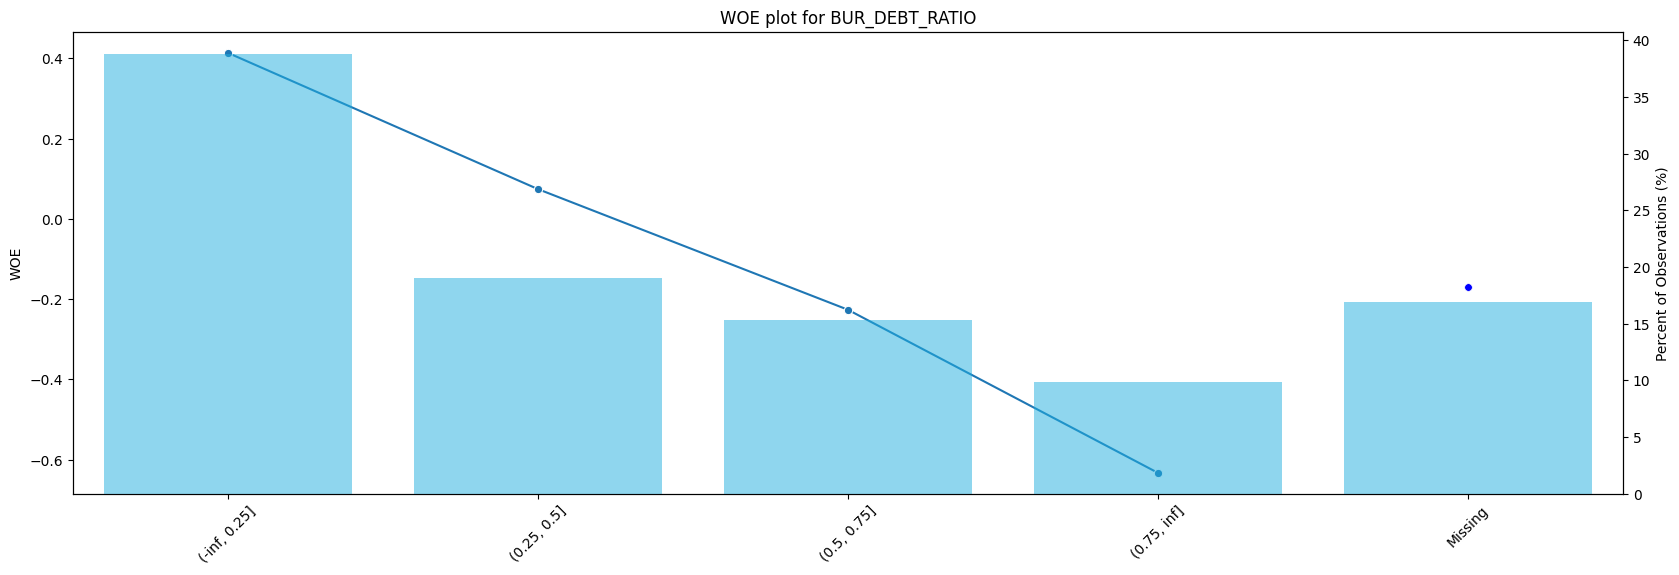

,Bin_Range,Count,Events,Non_Events,%_of_Events,%_of_Non_Events,WOE,IV,total_IV,Percent
0,"(-inf, 0.25]",19630,1233,18397,0.264820,0.400387,0.413384,0.056042,0.121768,38.791400
1,"(0.25, 0.5]",9651,830,8821,0.178265,0.191978,0.074111,0.001016,0.121768,19.071615
2,"(0.5, 0.75]",7770,876,6894,0.188144,0.150039,-0.226313,0.008624,0.121768,15.354517
3,"(0.75, inf]",4988,799,4189,0.171607,0.091168,-0.632497,0.050877,0.121768,9.856928
4,Missing,8565,918,7647,0.197165,0.166427,-0.169482,0.005209,0.121768,16.925539


In [19]:
import matplotlib.pyplot as plt                                   
import seaborn as sns

def woe_iv_plot(data, variable_name):                             
    variable_data = woe_iv(data)                                  
    print('IV for', variable_name, 'with', variable_data.shape[0]-1, 'numeric bins:',
          round(variable_data.loc[0, 'total_IV'], 4))
    fig, ax1 = plt.subplots(figsize=(20, 6))

    # WoE line for the numeric bins (Missing left out)
    if variable_data['Bin_Range'].isin(['Missing']).sum() > 0:
        sns.lineplot(data=variable_data['WOE'].iloc[0:-1], marker='o', ax=ax1)
    else:
        sns.lineplot(data=variable_data['WOE'], marker='o', ax=ax1)
    plt.xticks(rotation=45)

    # Missing as a separate dot
    if variable_data['Bin_Range'].isin(['Missing']).sum() > 0:
        last_point = len(variable_data['WOE']) - 1
        sns.scatterplot(x=[last_point], y=[variable_data['WOE'][last_point]], color='b', s=30, ax=ax1)

    # Bars: % of applicants in each bin, on a second y-axis
    ax2 = ax1.twinx()
    total_count = variable_data['Count'].sum()
    variable_data['Percent'] = (variable_data['Count'] / total_count) * 100
    sns.barplot(x=variable_data['Bin_Range'].astype(str),         
                y=variable_data['Percent'], alpha=0.5, ax=ax2, color='deepskyblue')
    ax2.set_ylabel('Percent of Observations (%)')

    plt.title("WOE plot for " + variable_name)
    plt.show()
    return variable_data                                       

w = dev[['BUR_DEBT_RATIO', 'TARGET']].copy()
w['Bin_Range'] = pd.cut(w['BUR_DEBT_RATIO'], bins=[-np.inf, 0.25, 0.50, 0.75, np.inf], include_lowest=True)
woe_iv_plot(w, 'BUR_DEBT_RATIO')

**(xii) testing other bureau features suggested in review**

*Development rows only. Built in a separate table (candidate_flags), so these do not enter the candidate list unless named below.*

- a) any credit sold or written off as bad debt (1,198 credits) - payment history
- b) ever overdue (AMT_CREDIT_MAX_OVERDUE > 0) - payment history
- adverse history: overdue now, an overdue amount ever recorded (a or b), or a credit sold or written off, in one flag
- c) debt ratio on active credits only (closed credits no longer dilute the denominator)
- d) MSR-style flag: repayment above 30% of income
- e) credit card utilisation: card debt / card credit, on all cards (same rule as the debt ratio), and as a test on active cards only

Results
- Bad debt/sold: IV 0.011, too weak on its own; ever overdue: IV 0.022, weak. Combined adverse-history flag: IV 0.033, stronger than either and than BUR_ANY_OVERDUE (0.022). Its IV is weak, but payment history is a core scorecard variable (number of delinquencies, FA7.2 s6), and a weaker variable may be kept for business reasons (FA10.2 s13). Candidate for Component 3.
- Active-only debt ratio (with the same fix 3): IV 0.103 vs 0.127 for the all-credit version, and it is blank for anyone with no active credit. Rejected - keep the all-credit debt ratio.
- Credit card utilisation: IV 0.097, and it measures amounts owed (total utilisation, FA7.2 s6) without depending on the historical loan. Blank means no bureau file, or no card with a known balance: structurally missing (FA9.1 s5), kept as its own bin. Candidate for Component 3.
- Active cards only: IV 0.091 against 0.097, and blank for 55.8% of development applicants against 49.9%. Rejected - keep the all-cards version, the same rule as the debt ratio.
- Repayment > 30% of income: IV 0.0004. Rejected as a scorecard variable; MSR/TDSR are applied as regulatory pre-screens instead (Assumptions: context and affordability). The annuity here belongs to the consumer loan, not a mortgage.


In [20]:
candidate_flags = merged[['SK_ID_CURR', 'TARGET', 'BUR_NONE', 'BUR_ANY_OVERDUE', 'BUR_DEBT_RATIO',
               'AMT_ANNUITY', 'AMT_INCOME_TOTAL']].copy()

# a) + b) payment-history flags, one row per applicant
bur['IS_BAD_OR_SOLD'] = bur['CREDIT_ACTIVE'].isin(['Sold', 'Bad debt'])
g = bur.groupby('SK_ID_CURR')
candidate_flags['BUR_ANY_BAD_OR_SOLD'] = candidate_flags['SK_ID_CURR'].map(g['IS_BAD_OR_SOLD'].max().astype(int))
ever = g['AMT_CREDIT_MAX_OVERDUE'].max()
candidate_flags['BUR_EVER_OVERDUE'] = candidate_flags['SK_ID_CURR'].map((ever > 0).astype(float).where(ever.notna()))
adverse = ((candidate_flags['BUR_ANY_OVERDUE'] == 1) | (candidate_flags['BUR_ANY_BAD_OR_SOLD'] == 1) | (candidate_flags['BUR_EVER_OVERDUE'] == 1))
candidate_flags['BUR_ANY_ADVERSE'] = adverse.astype(float).where(candidate_flags['BUR_NONE'] == 0)   # no-file applicants stay blank

# c) debt ratio on active credits only (negative debt already set to missing in (v))
act = bur[bur['CREDIT_ACTIVE'] == 'Active'].groupby('SK_ID_CURR')
ratio_active = (act['AMT_CREDIT_SUM_DEBT'].sum(min_count=1) / act['CREDIT_SUM_VALID'].sum()).replace([np.inf, -np.inf], np.nan)
candidate_flags['BUR_DEBT_RATIO_ACTIVE'] = candidate_flags['SK_ID_CURR'].map(ratio_active)

# d) MSR-style flag
candidate_flags['ANNUITY_INCOME_GT_30'] = (candidate_flags['AMT_ANNUITY'] / candidate_flags['AMT_INCOME_TOTAL'] > 0.30).astype(int)

# e) credit card utilisation: card debt / card credit, only cards where the debt is known (same fix 3 as the debt ratio)
card = bur[bur['CREDIT_TYPE'] == 'Credit card'].groupby('SK_ID_CURR')
utilisation = (card['AMT_CREDIT_SUM_DEBT'].sum(min_count=1) / card['CREDIT_SUM_VALID'].sum()).replace([np.inf, -np.inf], np.nan)
candidate_flags['BUR_CARD_UTIL'] = candidate_flags['SK_ID_CURR'].map(utilisation)   # blank = no bureau file, or no card with a known balance
# test: active cards only (not a candidate; Component 3 takes only BUR_ANY_ADVERSE and BUR_CARD_UTIL)
card_act = bur[(bur['CREDIT_TYPE'] == 'Credit card') & (bur['CREDIT_ACTIVE'] == 'Active')].groupby('SK_ID_CURR')
util_active = (card_act['AMT_CREDIT_SUM_DEBT'].sum(min_count=1) / card_act['CREDIT_SUM_VALID'].sum()).replace([np.inf, -np.inf], np.nan)
candidate_flags['BUR_CARD_UTIL_ACTIVE'] = candidate_flags['SK_ID_CURR'].map(util_active)

flags_dev = candidate_flags[candidate_flags['SK_ID_CURR'].isin(dev_ids)]   # outcomes are read on development rows only
print(flags_dev.groupby('BUR_ANY_ADVERSE', dropna=False)['TARGET'].agg(['count', 'mean']).round(4))
tested = ['BUR_ANY_BAD_OR_SOLD', 'BUR_EVER_OVERDUE', 'BUR_ANY_ADVERSE', 'BUR_ANY_OVERDUE',
          'BUR_DEBT_RATIO_ACTIVE', 'BUR_DEBT_RATIO', 'ANNUITY_INCOME_GT_30', 'BUR_CARD_UTIL', 'BUR_CARD_UTIL_ACTIVE']
print(pd.Series({c: fine_iv(c, flags_dev) for c in tested}).round(4))
print((flags_dev[['BUR_CARD_UTIL', 'BUR_CARD_UTIL_ACTIVE']].isna().mean() * 100).round(1))   # % blank

                 count    mean
BUR_ANY_ADVERSE               
0.0              30551  0.0797
1.0              12960  0.1096
NaN               7093  0.1129
BUR_ANY_BAD_OR_SOLD      0.0114
BUR_EVER_OVERDUE         0.0221
BUR_ANY_ADVERSE          0.0326
BUR_ANY_OVERDUE          0.0221
BUR_DEBT_RATIO_ACTIVE    0.1031
BUR_DEBT_RATIO           0.1273
ANNUITY_INCOME_GT_30     0.0004
BUR_CARD_UTIL            0.0972
BUR_CARD_UTIL_ACTIVE     0.0914
dtype: float64
BUR_CARD_UTIL           49.9
BUR_CARD_UTIL_ACTIVE    55.8
dtype: float64


## **COMPONENT 2: DATA SELECTION AND PREPARATION**

Summary:

The application file supplies 86 candidate columns, and Part B summarised the bureau data into 9 more features. Step (xii) builds 2 more bureau features in a separate table (`BUR_ANY_ADVERSE`, `BUR_CARD_UTIL`), so the bureau file gives 11 features in all.

We now engineer 5 more features: `AGE_YEARS` (Part A, segment selection), and `YEARS_EMPLOYED`, `CREDIT_INCOME_RATIO`, `ANNUITY_INCOME_RATIO` and `CREDIT_GOODS_RATIO` (section 2.1).

For Component 3, 35 columns stay in the table but are not candidates:
- `SK_ID_CURR`, `TARGET`: the ID and the label.
- `FLAG_OWN_REALTY`: always N after the segment filter.
- `DAYS_BIRTH`, `DAYS_EMPLOYED`: replaced by `AGE_YEARS` and `YEARS_EMPLOYED`.
- `CODE_GENDER`: left out for fairness reasons (FA7.1 s14).
- `BUR_NONE`: its information is already in each bureau feature's Missing bin.
- 28 `_MODE` / `_MEDI` columns: duplicates of the `_AVG` building statistics.

Column count, step by step:
- Start: `App_Data` with 120 columns.
- Part A (4 filters) adds `AGE_YEARS`: 121.
- Part B (summarise and left join) adds 9 bureau features and `BUR_NONE`: 131.
- Component 2 adds 4 features: 135.
- 35 columns are kept but not screened, leaving 100 candidates in this table.
- With the 2 features from (xii), Component 3 receives 102 candidates; it drops 3 that have a single value, and screens 99.
- The table has 72,292 rows.

**2.1: Creating application features**

Ratios capture relationships that lenders care about, such as loan against price, or repayment against income.

Each feature mirrors a lending consideration:
- **YEARS_EMPLOYED**: time in the current job, a measure of job stability and so of capacity to repay (FA7.1 s10). "Time at employment" is on the course's list of scorecard variables (FA7.2 s6). It is in the final Component 4 scorecard.
- **CREDIT_INCOME_RATIO**: loan size ÷ income, how stretched the borrower is.
- **ANNUITY_INCOME_RATIO**: repayment ÷ income. Similar in idea to the MSR (Mortgage Servicing Ratio, the share of income that can go to housing loans, capped at 30%) and the TDSR (Total Debt Servicing Ratio, the share that can go to all debt repayments, capped at 55%) (MAS, n.d.-b). Here it covers only this consumer loan's repayment, so it is a proxy, not the regulatory ratio.
- **CREDIT_GOODS_RATIO**: loan ÷ purchase price, like loan-to-value; above 1.0 means the loan also covers fees or insurance. It is not the regulatory LTV: a first Singapore housing loan is capped at 75% LTV (MAS, n.d.-a), below this ratio's whole range in the data (median 1.12).

In [21]:
merged = merged.copy()   # avoids PerformanceWarning
merged['YEARS_EMPLOYED']       = -merged['DAYS_EMPLOYED'] / 365.25   # 365.25 days a year (to account for leap years)
merged['CREDIT_INCOME_RATIO']  = merged['AMT_CREDIT'] / merged['AMT_INCOME_TOTAL']
merged['ANNUITY_INCOME_RATIO'] = merged['AMT_ANNUITY'] / merged['AMT_INCOME_TOTAL']
merged['CREDIT_GOODS_RATIO']   = merged['AMT_CREDIT'] / merged['AMT_GOODS_PRICE']
print(merged[['YEARS_EMPLOYED', 'CREDIT_INCOME_RATIO','ANNUITY_INCOME_RATIO', 'CREDIT_GOODS_RATIO']].describe().round(3).T)

                        count   mean    std    min    25%    50%    75%  \
YEARS_EMPLOYED        72292.0  5.923  5.627  0.000  1.958  4.227  8.027   
CREDIT_INCOME_RATIO   72292.0  4.042  2.667  0.100  2.107  3.333  5.300   
ANNUITY_INCOME_RATIO  72284.0  0.181  0.093  0.008  0.116  0.164  0.230   
CREDIT_GOODS_RATIO    72242.0  1.119  0.125  0.150  1.000  1.116  1.198   

                         max  
YEARS_EMPLOYED        36.972  
CREDIT_INCOME_RATIO   33.333  
ANNUITY_INCOME_RATIO   1.185  
CREDIT_GOODS_RATIO     3.000  


**2.2: Creating candidate columns for COMPONENT 3**

Results
- 7 named + 28 duplicates (14 triples x 2) = 35 excluded
- Table has 131 + 4 new features = 135 columns, 135-35 = 100 candidates, plus `BUR_ANY_ADVERSE` and `BUR_CARD_UTIL` from (xii) = 102 that go to Component 3 (99 after it removes 3 single-valued fields).

In [22]:
exclude = ['SK_ID_CURR', 'TARGET',           # ID and label
           'CODE_GENDER',                    # protected attribute (FA7.1 s14)
           'DAYS_BIRTH', 'DAYS_EMPLOYED',    # replaced by AGE_YEARS, YEARS_EMPLOYED
           'FLAG_OWN_REALTY',                # 'N' for everyone after Step 1
           'BUR_NONE']                       # absorbed by the Missing bins
exclude += [c for c in merged.columns
            if c.endswith(('_MODE', '_MEDI')) and c[:-5] + '_AVG' in merged.columns]
candidates = [c for c in merged.columns if c not in exclude]
print(len(exclude), len(candidates))

35 100


**2.3: Notes for Components 3 and 4 (from review), and what was decided**

1. **Loan-size variables may not carry over to a mortgage.** `AMT_GOODS_PRICE`, `AMT_CREDIT` and `AMT_ANNUITY` describe the historical consumer loan. A real first-property applicant would bring a property price far outside the training range, so every applicant would fall into the top bin. `CREDIT_GOODS_RATIO` has a related problem (a mortgage LTV of at most 0.75 sits below its whole training range). **Decided:** Component 3 excludes these variables, accepting some loss of predictive power.
2. **`EXT_SOURCE_1`** is missing for 48.5% of training applicants, just under the 50% cut-off. Reason to keep it: being missing is itself informative (10.2% Bad when missing against 8.2% when present, on the training rows), and it plays the role a credit bureau score would (FA7.2 s7). **Decided:** kept; it is the strongest characteristic in both final scorecards.
3. **Bin size:** coarse classing keeps at least 5% of rows per bin (FA10.3 s11), not 1%.
4. **`REG_CITY_NOT_LIVE_CITY` and `REG_CITY_NOT_WORK_CITY`** are not duplicates (correlation 0.49; 12% against 32% of applicants flagged). **Decided:** both are left out of the scorecard in Component 4, because Singapore is a single city and the flags could not be collected for a local applicant.
5. **Fairness:** gender is excluded, but age, education and region can act as proxies. **Decided:** Component 4 leaves them out of the scorecard and measures approval and default rates for every customer group directly (FA7.1 s14).
6. **New candidate `BUR_ANY_ADVERSE`** from (xii), IV 0.033. It is in the final scorecard for applicants with a bureau file.
7. **New candidate `BUR_CARD_UTIL`** from (xii), IV 0.097: credit card debt ÷ card credit. Total utilisation is on the FA7.2 s6 variable list. Blank means no bureau file or no card with a known balance. It is in the final scorecard for applicants with a bureau file.

**2.4: Data exploration**

*Development rows only. The test applicants play no part in this.*

Data exploration helps us choose which data to use, spot problems and interpret later results (FA7.3 s3). We use the charts of the Week 7 lab on the main numerical and categorical fields of the segment. Nothing here feeds the model.

                             mean        std       min        25%        50%        75%         max
AMT_INCOME_TOTAL        170214.62  100721.34  25650.00  112500.00  157500.00  202500.00  4500000.00
AGE_YEARS                   37.65       8.68     21.02      30.43      37.16      44.14       55.00
YEARS_EMPLOYED               5.92       5.63      0.00       1.96       4.23       8.02       36.97
EXT_SOURCE_1                 0.45       0.20      0.01       0.29       0.44       0.61        0.94
OWN_CAR_AGE                 12.00      11.61      0.00       5.00       9.00      15.00       91.00
DAYS_LAST_PHONE_CHANGE    -987.78     841.96  -4292.00   -1615.00    -786.00    -265.00        0.00
BUR_DEBT_RATIO               0.33       0.32      0.00       0.00       0.29       0.56       16.79
BUR_MEAN_DAYS_CREDIT     -1052.04     562.69  -2922.00   -1403.21   -1010.18    -627.88       -2.00
BUR_NEWEST_DAYS           -486.82     529.08  -2922.00    -623.00    -303.00    -142.00       -2.00


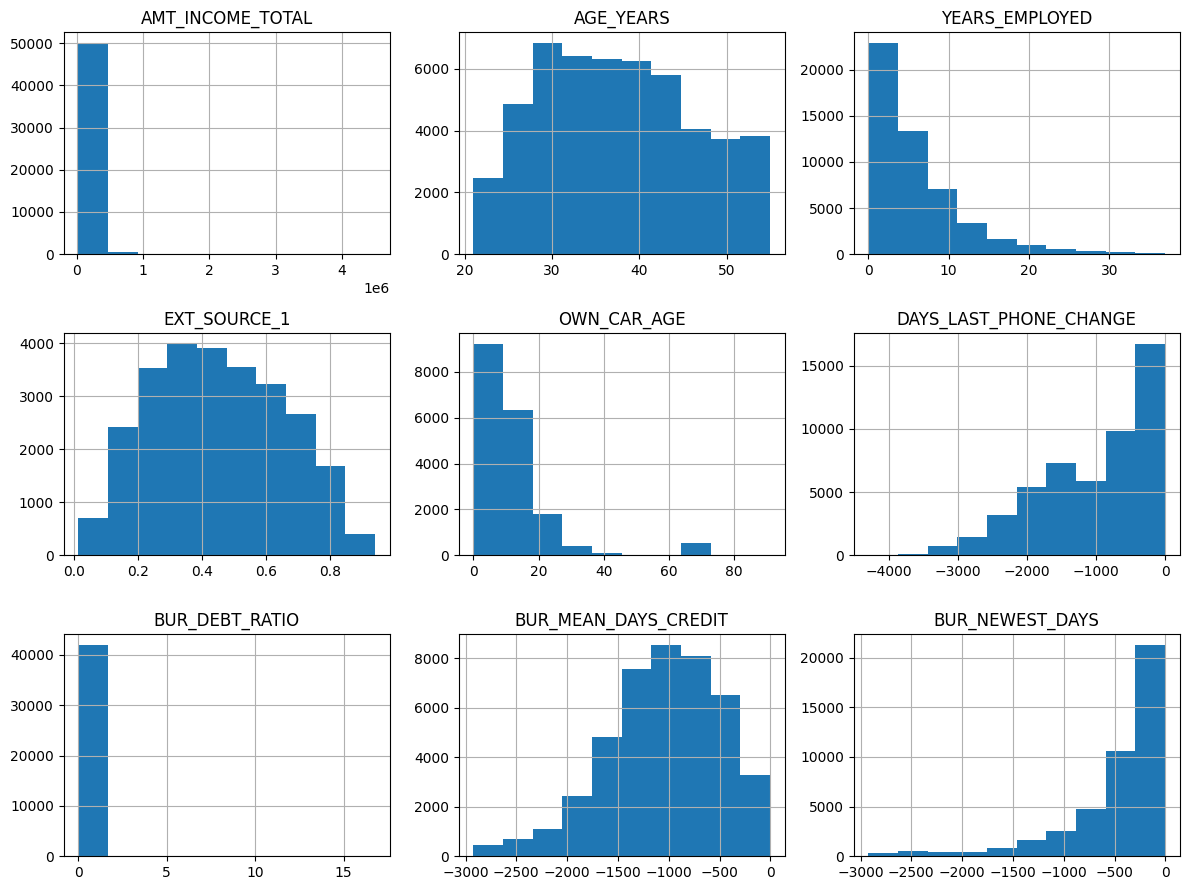

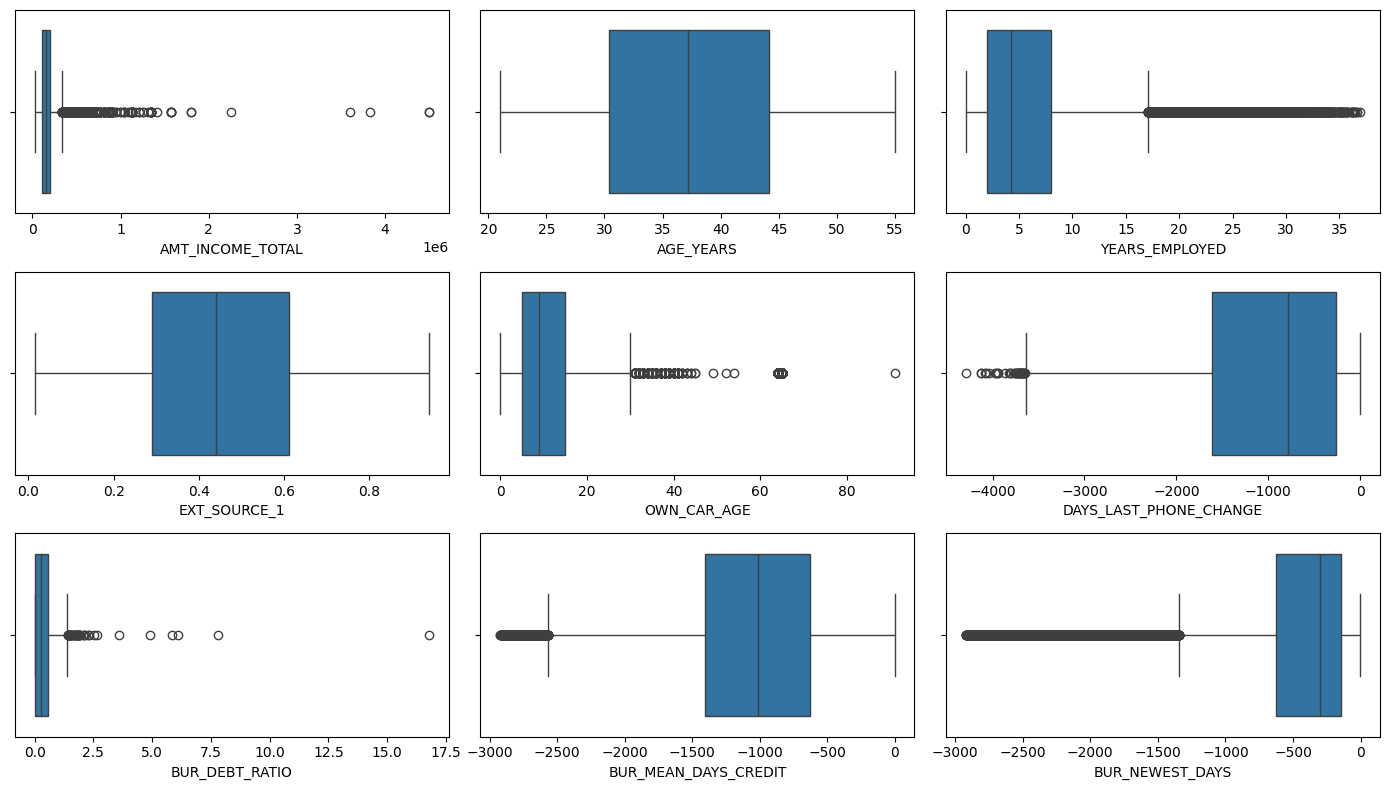

Applicants with |z| > 3:
AMT_INCOME_TOTAL           473
AGE_YEARS                    0
YEARS_EMPLOYED            1071
EXT_SOURCE_1                 0
OWN_CAR_AGE                547
DAYS_LAST_PHONE_CHANGE      66
BUR_DEBT_RATIO              48
BUR_MEAN_DAYS_CREDIT       231
BUR_NEWEST_DAYS           1339
Largest income: 4500000.0 | median income: 157500.0


In [23]:
eda = merged[merged['SK_ID_CURR'].isin(dev_ids)]
eda_numeric = ['AMT_INCOME_TOTAL', 'AGE_YEARS', 'YEARS_EMPLOYED', 'EXT_SOURCE_1', 'OWN_CAR_AGE', 'DAYS_LAST_PHONE_CHANGE',
               'BUR_DEBT_RATIO', 'BUR_MEAN_DAYS_CREDIT', 'BUR_NEWEST_DAYS']
eda_categorical = ['NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE']

# univariate: summary statistics (FA7.3 s5; Week 7 lab)
print(eda[eda_numeric].describe().iloc[1:].T.round(2).to_string())
print(eda[eda_categorical].describe(include='all').T.to_string())

# univariate: histograms (FA7.3 s6; Week 7 lab)
eda[eda_numeric].hist(figsize=(12, 9))
plt.tight_layout()
plt.show()

# outliers: boxplots (FA7.3 s8-9; Week 7 lab)
fig, axes = plt.subplots(ncols=3, nrows=3, figsize=(14, 8))
for i, axis in enumerate(fig.axes):
    sns.boxplot(ax=axis, data=eda[eda_numeric[i]], orient='h')
    axis.set_xlabel(eda_numeric[i])
plt.tight_layout()
plt.show()

# outliers: z-scores, |z| > 3 (FA7.3 s16)
z = (eda[eda_numeric] - eda[eda_numeric].mean()) / eda[eda_numeric].std()
print('Applicants with |z| > 3:')
print((z.abs() > 3).sum().to_string())
print('Largest income:', eda['AMT_INCOME_TOTAL'].max(), '| median income:', eda['AMT_INCOME_TOTAL'].median())

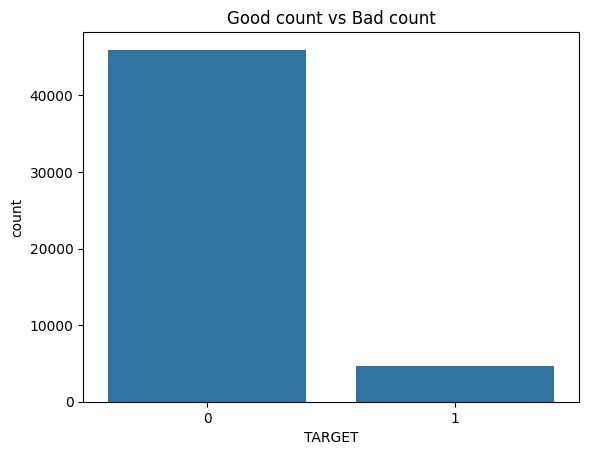

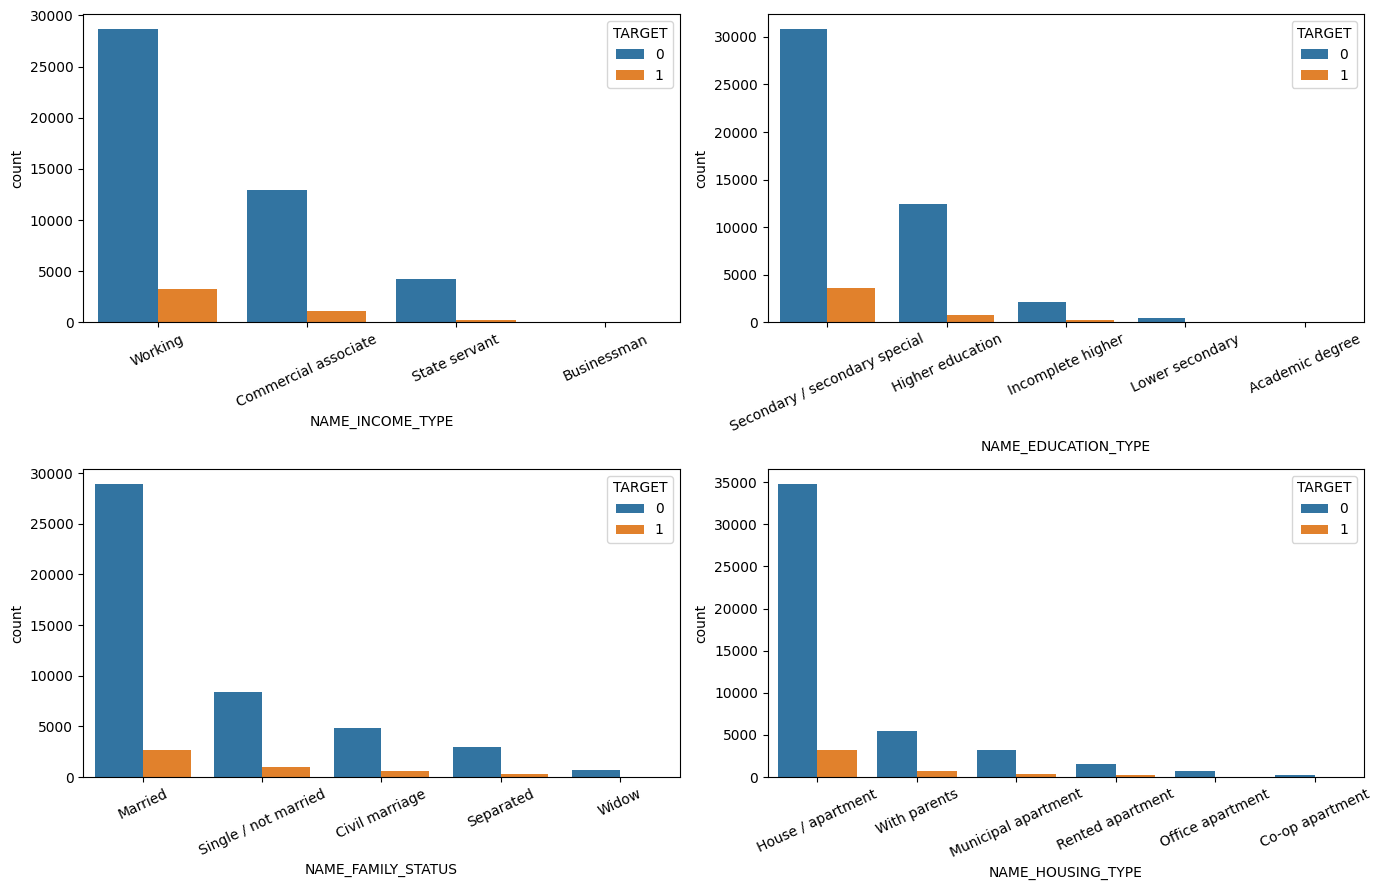

                      count    mean
NAME_INCOME_TYPE                   
Businessman               1  0.0000
State servant          4566  0.0624
Commercial associate  14086  0.0781
Working               31951  0.1024
                               count    mean
NAME_EDUCATION_TYPE                         
Academic degree                   25  0.0000
Higher education               13211  0.0565
Incomplete higher               2368  0.0938
Secondary / secondary special  34436  0.1046
Lower secondary                  564  0.1489
                      count    mean
NAME_FAMILY_STATUS                 
Widow                   763  0.0629
Married               31659  0.0853
Separated              3270  0.0924
Civil marriage         5466  0.1067
Single / not married   9446  0.1084
                     count    mean
NAME_HOUSING_TYPE                 
Office apartment       738  0.0637
House / apartment    38075  0.0852
Municipal apartment   3507  0.0989
Co-op apartment        256  0.1016
With pa

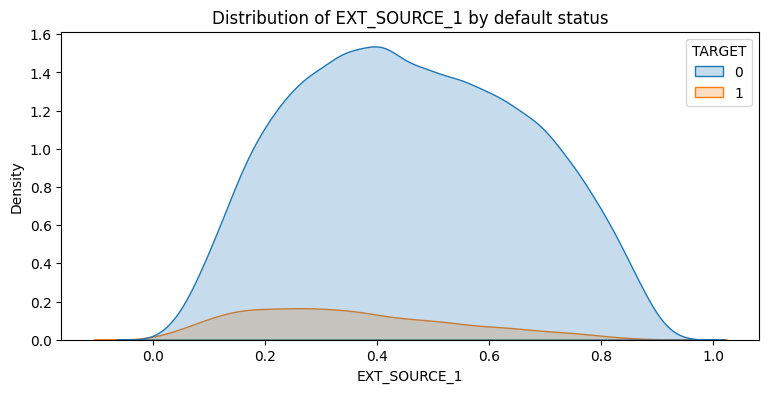

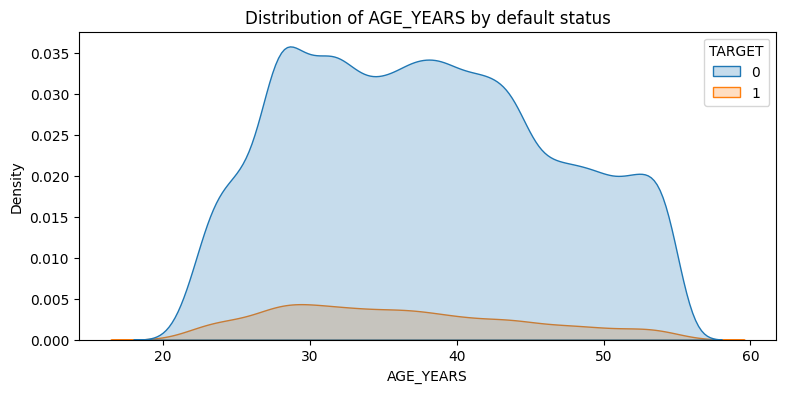

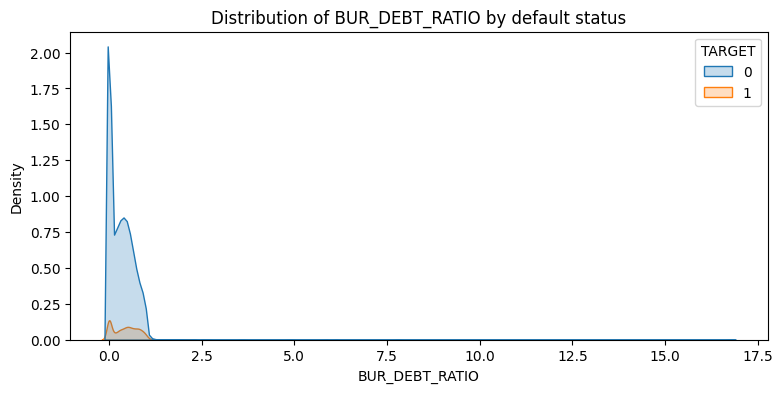

TARGET                           0           1
AMT_INCOME_TOTAL        171297.017  159532.924
AGE_YEARS                   37.813      36.026
YEARS_EMPLOYED               6.046       4.693
EXT_SOURCE_1                 0.460       0.350
OWN_CAR_AGE                 11.893      13.273
DAYS_LAST_PHONE_CHANGE   -1002.508    -842.438
BUR_DEBT_RATIO               0.321       0.437
BUR_MEAN_DAYS_CREDIT     -1066.969    -898.457
BUR_NEWEST_DAYS           -494.539    -407.376


In [24]:
# goods against bads (Week 7 lab)
sns.countplot(x=eda['TARGET'])
plt.title('Good count vs Bad count')
plt.show()

# univariate: bar charts of the categorical fields (FA7.3 s10; Week 7 lab)
# bivariate: goods and bads in each category (FA7.3 s12; Week 7 lab)
fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(14, 9))
for i, axis in enumerate(fig.axes):
    sns.countplot(ax=axis, x=eda[eda_categorical[i]], hue=eda['TARGET'], order=eda[eda_categorical[i]].value_counts(ascending=False).index)
    axis.set_xlabel(eda_categorical[i])
    axis.tick_params(axis='x', labelrotation=25)
plt.tight_layout()
plt.show()
for c in eda_categorical:
    print(eda.groupby(c)['TARGET'].agg(['count', 'mean']).round(4).sort_values('mean').to_string())

# bivariate: KDE of goods and bads (FA7.3 s11; Week 7 lab)
for v in ['EXT_SOURCE_1', 'AGE_YEARS', 'BUR_DEBT_RATIO']:
    plt.figure(figsize=(9, 4))
    sns.kdeplot(data=eda, x=v, hue='TARGET', fill=True)
    plt.title('Distribution of ' + v + ' by default status')
    plt.show()
print(eda.groupby('TARGET')[eda_numeric].mean().round(3).T.to_string())

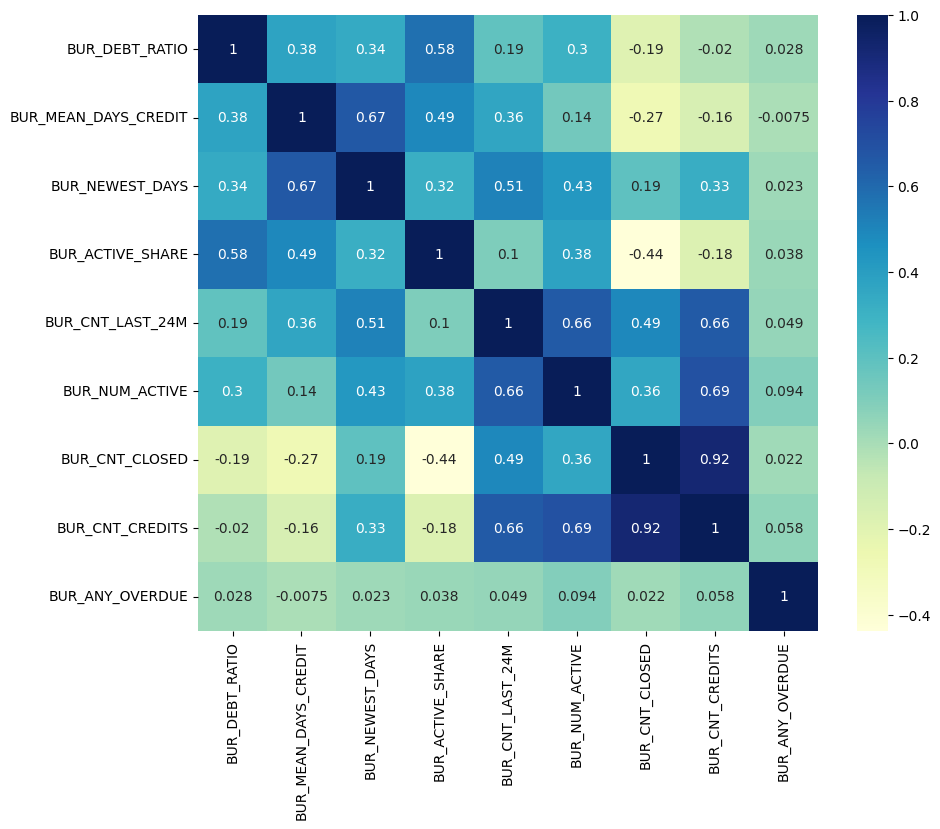

Bureau pairs correlated above 0.8:
BUR_CNT_CLOSED   BUR_CNT_CREDITS    0.919
BUR_CNT_CREDITS  BUR_CNT_CLOSED     0.919
Columns missing values (share of development rows):
AMT_INCOME_TOTAL          0.0000
AGE_YEARS                 0.0000
YEARS_EMPLOYED            0.0000
EXT_SOURCE_1              0.4853
OWN_CAR_AGE               0.6366
DAYS_LAST_PHONE_CHANGE    0.0000
BUR_DEBT_RATIO            0.1693
BUR_MEAN_DAYS_CREDIT      0.1402
BUR_NEWEST_DAYS           0.1402
NAME_INCOME_TYPE          0.0000
NAME_EDUCATION_TYPE       0.0000
NAME_FAMILY_STATUS        0.0000
NAME_HOUSING_TYPE         0.0000
Rows with more than one missing value: 20852 of 50604


In [25]:
# bivariate: correlation heat map of the bureau features (FA7.3 s13; Week 7 lab)
eda_bureau = ['BUR_DEBT_RATIO', 'BUR_MEAN_DAYS_CREDIT', 'BUR_NEWEST_DAYS', 'BUR_ACTIVE_SHARE', 'BUR_CNT_LAST_24M',
              'BUR_NUM_ACTIVE', 'BUR_CNT_CLOSED', 'BUR_CNT_CREDITS', 'BUR_ANY_OVERDUE']
cor = eda[eda_bureau].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cor, xticklabels=cor.columns, yticklabels=cor.columns, annot=True, cmap='YlGnBu', ax=ax)
plt.show()
print('Bureau pairs correlated above 0.8:')
print(cor.unstack()[(cor.unstack().abs() > 0.8) & (cor.unstack().abs() < 1)].round(3).to_string())

# missing values by column and by row (FA7.3 s14; Week 7 lab)
print('Columns missing values (share of development rows):')
print((eda[eda_numeric + eda_categorical].isnull().sum() / eda.shape[0]).round(4).to_string())
print('Rows with more than one missing value:', eda[eda[eda_numeric + eda_categorical].isnull().sum(axis=1) > 1].shape[0], 'of', eda.shape[0])

**How to read it.**
- **Distributions.** Income is strongly right-skewed: the median is 157,500 and the largest value is 4,500,000 (the data is not in SGD). Age is spread evenly over the segment's 21-55 range. Job tenure and car age are also right-skewed.
- **Outliers.** The boxplots and z-scores (|z| > 3, FA7.3 s16) flag 473 applicants on income, 1,071 on job tenure and 547 on car age. These are valid observations, such as a high earner or a long-serving employee, unlike the invalid values already treated in this notebook, such as the 365,243-day employment placeholder and negative debt. So we do not delete or truncate them (FA9.1 s7-8): they stay in the data and fall into the top or bottom bin in coarse classing, which limits their effect (FA10.4 s8).
- **Goods against Bads.** About 9% of applicants are Bads, so the classes are imbalanced (FA9.3 s20), and the Bads' KDE curves look small next to the Goods'. On average, Bads have a lower external score (0.35 against 0.46), a higher debt ratio (0.44 against 0.32), a shorter time in the job (4.7 years against 6.0) and are slightly younger (36.0 against 37.8). These directions make business sense.
- **Categories.** Bad rates run from 5.7% with higher education to 14.9% with lower secondary education, and from 8.5% in a house or apartment to 13.1% in a rented one. Some categories are tiny (1 businessman, 25 with an academic degree), so they must be merged in classing.
- **Redundancy.** In the heat map, only `BUR_CNT_CLOSED` and `BUR_CNT_CREDITS` are correlated above 0.8 (0.92), because total credits is mostly closed credits. Section (x) tests these two, and total credits does not go forward.
- **Missing values.** They are concentrated in particular columns for known reasons: `OWN_CAR_AGE` is 64% blank (no car), `EXT_SOURCE_1` 49%, and the bureau features 14-17% (no file, or no usable debt data). So 20,852 of 50,604 rows have more than one blank. Most of this is structural, so Missing is kept as its own attribute rather than filled in (FA9.1 s5-6, FA10.4 s7).

## References
Web pages were accessed in November 2026.

*Course material* (cited in the text as FA*module* s*slide*)
- IS453 Financial Analytics. (2026). *Module 7.1: Lending credit risk overview; 7.2: Credit scorecard concepts; 7.3: Data exploration* [Lecture slides]. Singapore Management University.
- IS453 Financial Analytics. (2026). *Module 9.1: Data preparation; 9.2: Data merging; 9.3: ML for credit analysis* [Lecture slides]. Singapore Management University.
- IS453 Financial Analytics. (2026). *Module 10.1: Weight of evidence; 10.2: Characteristic screening; 10.3: Coarse classing; 10.4: Data normalisation* [Lecture slides]. Singapore Management University.
- IS453 Financial Analytics. (2026). *Week 7, Week 9, Week 10 and Week 11 labs* [Lab notebooks], including `scorecardpy` 0.1.9.7. Singapore Management University.
- IS453 Financial Analytics. (2026). *IS453 Group Assignment - Data* and *Data Dict* [Data set]. Singapore Management University.

*Other sources*
- Housing & Development Board. (2026). *CPF housing grants for HDB flat buyers*. MyNiceHome. https://www.mynicehome.gov.sg/get-started/hdb-grants-guide/
- Housing & Development Board. (n.d.). *Couples and families: Flat and grant eligibility*. https://www.hdb.gov.sg/cs/infoweb/residential/buying-a-flat/understanding-your-eligibility-and-housing-loan-options/flat-and-grant-eligibility/couples-and-families
- Ministry of Manpower. (n.d.). *Retirement*. https://www.mom.gov.sg/employment-practices/retirement
- Monetary Authority of Singapore. (n.d.-a). *Loan tenure and loan-to-value limits*. https://www.mas.gov.sg/regulation/explainers/new-housing-loans/loan-tenure-and-loan-to-value-limits
- Monetary Authority of Singapore. (n.d.-b). *Mortgage Servicing Ratio and Total Debt Servicing Ratio rules*. https://www.mas.gov.sg/regulation/explainers/new-housing-loans/msr-and-tdsr-rules
- PropKaki. (2026). *How much does a 4-room HDB cost?* https://propkaki.sg/market/questions/how-much-does-a-4-room-hdb-cost (island-wide 4-room median, secondary source)
